# Mini Project: Classification with Naive Bayes
## Predicting Supply Chain Disruptions (Global Supply Chain Risk 2026)

### What this notebook covers:
- Problem definition
- Algorithm explanation (Naive Bayes, and why we start with (Gaussian Naive Bayes))
- Data preprocessing
- Exploratory Data Analysis (EDA)
- Prepare Data for modeling
- Model training and Model evaluation
- Fixing the weaknesses of Naive Bayes
- Comparing Naive Bayes with other classification models
- Conclusion and key insights

## 1. Problem Definition and Understanding

We worked with the (Supply Chain Risk 2026 dataset). Each row is one shipment travelling between two internaional ports.

### 1.1 What are we predicting?
Our target variable is (`Disruption_Occurred`) which is either:

1- The shipment (was disrupted) maybe delayed, rerouted, or blocked

0- The shipment (arrived normally)

Because the target has only two possible values, then it's a (binary classification) problem.

### Why does this matter?
 if company can predict before departure wheather a shipment will possiably get  disrputed they can change the route , choose another carier or notify the customers. Meaning our model will use only information that is known before the shipment leaves.

### 1.2 Key Questions
While analyzing we will answer:
- Which feature are linked to disruptions? (weather, geopolitical risk, carrier reliability, ...)
- will transport mode, product type, or ports change the disruption rate?
- Can Naive Bayes predict disruptions well, and how does it compare with other models?

## 2. Algorithm Explanation: Naive Bayes

### 2.1 What is Naive Bayes?
Naive Bayes is a family of probabilistic classifiers. Instead of drawing a boundary between classes directly, it calculates
the probability of each class given the features and picks the class with the highest probability.
### 2.2 Why is it called "Naive"?
Calculating $P(\text{Features} \mid \text{Class})$ for many features together is very hard.
Naive Bayes makes a simplifying ("naive") assumption: all features are **independent of each other** inside each class.
This lets us multiply simple, one-feature probabilities.

### 2.3 How does it work? (Step by step)
1. **Learn the priors:** count how often each class appears in the training data.
2. **Learn the likelihoods:** for each feature and each class, learn the distribution of values.
3. **Predict:** for a new shipment, multiply the prior by all the likelihoods for each class.
4. **Choose** the class with the highest result (in practice, logs are added instead of multiplying, to avoid very small numbers).

### 2.4 Types of Naive Bayes

**Gaussian NB**:a Normal (bell-shaped) distribution  Continuous numbers (distance, scores)

**Categorical NB**:a categorical distribution (counts per category)  Categorical features (weather, port, mode)

**Multinomial NB**:counts Word counts in text
**Bernoulli NB**: 0/1 values  Binary features (word present or not)

### 2.5 Why Gaussian Naive Bayes?
We start with **Gaussian Naive Bayes** as our main model for fourreasons:
- Most of our important predictors are **continuous numbers**: for example `Geopolitical_Risk_Score`, `Carrier_Reliability_Score`, `Fuel_Price_Index`, `Distance_km`, `Weight_MT`. Gaussian NB is designed for continuous features.
- It is the **standard starting point** in scikit-learn (`GaussianNB`) and did not need special data format.
- It is **very fast** and gives **probabilities**, which are useful for risk scoring (example "this shipment has an 85% risk of disruption").
- Our numeric features are **almost uncorrelated** with each other (we confirm this in the EDA), so the "naive" independence assumption is useful for this dataset.

However, Gaussian NB also assumed every feature is **bell-shaped**. Our categorical features (like `Weather_Condition`) are not.
Later in the notebook we will **see this problem in the results**, explain it, and **fix it** with improved Naive Bayes versions.

### 2.6 When should Naive Bayes be used?
- When you need a **fast, simple baseline** model.
- When the dataset is **small** (it needs little data to learn).
- When features are **reasonably independent**.
- When you need **probability outputs** for ranking or risk scoring.
- Classic use cases: spam filtering, text classification, medical diagnosis, risk scoring.

### 2.7 Advantages and Limitations

**Advantages**

1- Very fast to train and predict. this matters becase training is just counting and averaging, no iterations

2- Works well with small datasets. this matters becase few parameters to learn (one mean and variance per feature per class)

3- Gives probabilities. this matters becase useful for risk ranking, not just yes/no

4- Simple and easy to explain. this matters becase every prediction can be traced to priors and likelihoods

5-Handles many features well. this matters becase each feature is treated separately, so it scales easily

6- Not sensitive to irrelevant features. this matters becase useless features have similar likelihoods for both classes, so they cancel out

**Limitations**

**1. Independence assumption**. what gose wrong Correlated features are "counted twice", making the model over-confident

**2. Normal distribution assumption (Gaussian NB)**. what gose wrong Skewed, uniform, or 0/1 features do not fit a bell curve

**3. Zero-frequency / zero-variance problem**. what gose wrong is If a value never appears with a class in training, its probability becomes 0 (or the variance becomes 0), which dominates the whole prediction

**4. Class imbalance**. what gose wrong is The prior pushes predictions toward the majority class, Adjust the `priors` parameter or tune the decision threshold

**5. Poorly calibrated probabilities**. what gose wrong is Probabilities tend to be too close to 0 or 1

**6. Cannot learn feature interactions**. what gose wrong It cannot learn rules like "storm **and** high risk"

In **Section 7** we apply fixes 2 and 3 directly and measure the improvement.

## 3. Data Preprocessing


In [ ]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing and model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV,cross_val_score
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.pipeline import make_pipeline
from sklearn.base import BaseEstimator, ClassifierMixin

# Models
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

# Utilities
import warnings
warnings.filterwarnings("ignore")

# Plot Style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # used everywhere so results are reproducible


### 3.1 Load the Dataset


In [ ]:
df = pd.read_csv("global_supply_chain_risk_2026.csv")

### 3.2 Data Understanding

In [ ]:
df.head()

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,10/16/2025,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,4/24/2024,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,1/26/2024,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,10/8/2024,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,9/7/2024,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1


In [ ]:
df.tail()

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
4995,SC-14995,11/10/2025,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0
4996,SC-14996,11/23/2025,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0
4997,SC-14997,10/18/2025,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0
4998,SC-14998,1/29/2025,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1
4999,SC-14999,6/1/2024,Dubai,Shanghai,Air,Textiles,9161.03,109.35,2.03,1.7,Storm,0.976,1.43,1


In [ ]:
df.shape

(5000, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Shipment_ID                5000 non-null   object 
 1   Date                       5000 non-null   object 
 2   Origin_Port                5000 non-null   object 
 3   Destination_Port           5000 non-null   object 
 4   Transport_Mode             5000 non-null   object 
 5   Product_Category           5000 non-null   object 
 6   Distance_km                5000 non-null   float64
 7   Weight_MT                  5000 non-null   float64
 8   Fuel_Price_Index           5000 non-null   float64
 9   Geopolitical_Risk_Score    5000 non-null   float64
 10  Weather_Condition          5000 non-null   object 
 11  Carrier_Reliability_Score  5000 non-null   float64
 12  Lead_Time_Days             5000 non-null   float64
 13  Disruption_Occurred        5000 non-null   int64

In [ ]:
df.describe().round(2)

,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,7704.06,246.25,2.85,5.08,0.75,19.36,0.61
std,4199.69,142.52,0.96,2.88,0.14,31.41,0.49
min,500.17,1.03,1.20,0.00,0.50,0.50,0.00
25%,4036.01,124.33,2.02,2.60,0.63,2.11,0.00
50%,7750.12,243.50,2.84,5.10,0.76,8.25,1.00
75%,11347.46,366.96,3.71,7.50,0.88,21.21,1.00
max,14995.91,499.75,4.50,10.00,1.00,236.39,1.00


In [ ]:
df.describe(include="object")

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Weather_Condition
count,5000,5000,5000,5000,5000,5000,5000
unique,5000,731,8,9,4,5,5
top,SC-14999,10/29/2024,Busan,Marseille,Air,Electronics,Fog
freq,1,16,667,583,1320,1016,1036


### Understanding the Columns

**Feature types:**
- **Numerical:** Distance_km, Weight_MT, Fuel_Price_Index, Geopolitical_Risk_Score, Carrier_Reliability_Score, Lead_Time_Days
- **Categorical:** Origin_Port, Destination_Port, Transport_Mode, Product_Category, Weather_Condition
- **Date:** Date
- **Target:** Disruption_Occurred (Classification)

### 3.3 Data Cleaning and Quality Checks


In [ ]:
df.isna().sum()

,0
Shipment_ID,0
Date,0
Origin_Port,0
Destination_Port,0
Transport_Mode,0
Product_Category,0
Distance_km,0
Weight_MT,0
Fuel_Price_Index,0
Geopolitical_Risk_Score,0


In [ ]:
print("Duplicated rows        :", df.duplicated().sum())
print("Duplicated Shipment_ID :", df["Shipment_ID"].duplicated().sum())

Duplicated rows        : 0
Duplicated Shipment_ID : 0


In [ ]:
# Date column changed to date type
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
df["Date"].dtype

Date range: 2024-01-01 to 2025-12-31


dtype('<M8[ns]')

In [ ]:
# check invalid values
checks = {
    "Negative distance" : (df["Distance_km"] <= 0).sum(),
    "Negative weight"   : (df["Weight_MT"] <= 0).sum(),
    "Risk score outside 0-10" : (~df["Geopolitical_Risk_Score"].between(0, 10)).sum(),
    "Reliability outside 0-1" : (~df["Carrier_Reliability_Score"].between(0, 1)).sum(),
    "Origin port = Destination port" : (df["Origin_Port"] == df["Destination_Port"]).sum(),
    "Target not 0/1" : (~df["Disruption_Occurred"].isin([0, 1])).sum(),
}
pd.Series(checks, name="Invalid rows")

,Invalid rows
Negative distance,0
Negative weight,0
Risk score outside 0-10,0
Reliability outside 0-1,0
Origin port = Destination port,0
Target not 0/1,0


In [ ]:
numeric_cols = ["Distance_km", "Weight_MT", "Fuel_Price_Index",
                "Geopolitical_Risk_Score", "Carrier_Reliability_Score", "Lead_Time_Days"]

def count_iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

pd.DataFrame({
    "Outliers (IQR)": [count_iqr_outliers(df[c]) for c in numeric_cols],
    "Skewness": [round(df[c].skew(), 2) for c in numeric_cols],
}, index=numeric_cols)

,Outliers (IQR),Skewness
Distance_km,0,0.00
Weight_MT,0,0.05
Fuel_Price_Index,0,0.01
Geopolitical_Risk_Score,0,-0.04
Carrier_Reliability_Score,0,-0.03
Lead_Time_Days,518,3.35


### Cleaning Summary
- **No missing values** and **no duplicates**
- `Date` was converted from text to datetime type.
- **No invalid values**: all scores are inside their valid ranges
- Only `Lead_Time_Days` has outliers and strong right skew. These are **real long delays**, not data entry errors, so we keep them for the EDA.
- The other numerical columns have skewness near 0 and no outliers.

## 4. Exploratory Data Analysis (EDA)

We explore the target, then each feature on its own (univariate), then each feature against the target (bivariate).

### 4.1 Target Variable: How common are disruptions?

                     Count  Percent
Disruption_Occurred                
1                     3063     61.3
0                     1937     38.7


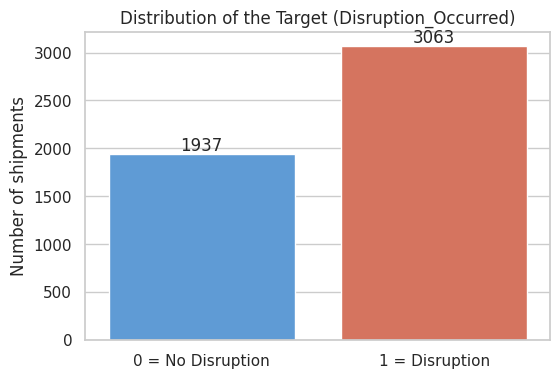

In [ ]:
target_counts = df["Disruption_Occurred"].value_counts()
target_pct = df["Disruption_Occurred"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"Count": target_counts, "Percent": target_pct}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Disruption_Occurred", palette=["#4C9BE8", "#E8684C"])
ax.set_xticklabels(["0 = No Disruption", "1 = Disruption"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribution of the Target (Disruption_Occurred)")
plt.xlabel("")
plt.ylabel("Number of shipments")
plt.show()

Insight: About 61% of shipments are disrupted and 39% are not. The classes are mildly imbalanced.
This is why we will use a stratified train/test split.


### 4.2 Univariate Analysis: Numerical Features (Histograms)

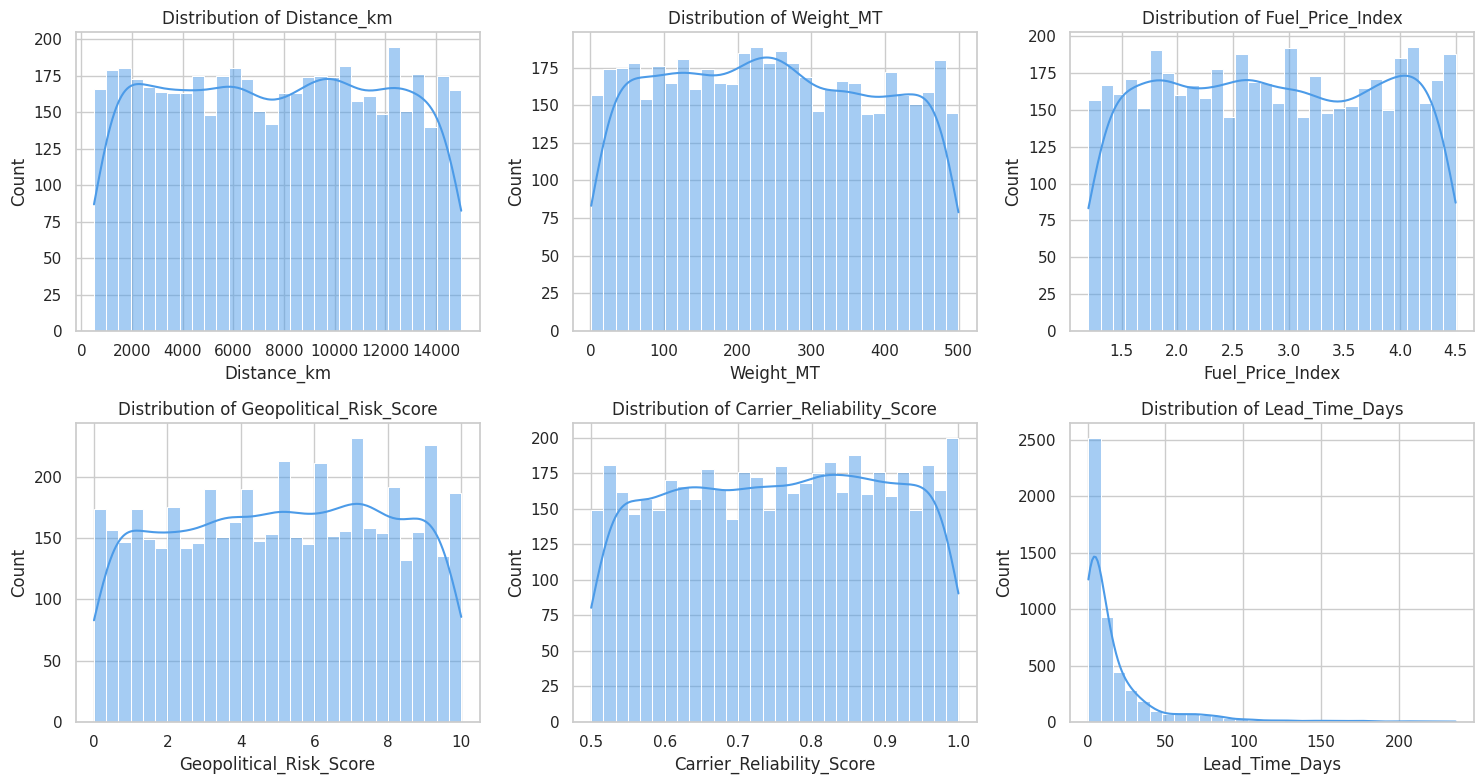

In [ ]:
model_numeric = ["Distance_km", "Weight_MT", "Fuel_Price_Index",
                 "Geopolitical_Risk_Score", "Carrier_Reliability_Score"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#4C9BE8")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

**Insights — Feature Distributions:** The histograms show three types of distributions:

**1. Uniform:** `Distance_km`, `Weight_MT`, `Fuel_Price_Index`
- all value ranges appear about equally often no value is more common than the others.

**2. Bell-shaped:** `Geopolitical_Risk_Score`, `Carrier_Reliability_Score`
- most values cluster around the mean and become less frequent toward both ends.

**3. Right-skewed:** `Lead_Time_Days`
- most shipments take under 20 days, but a long tail extends to the right: a few shipments take more than 100 days (long delays).
- these extreme values pull the mean above the median.

### 4.3 Univariate Analysis: Boxplots (Spread and Outliers)

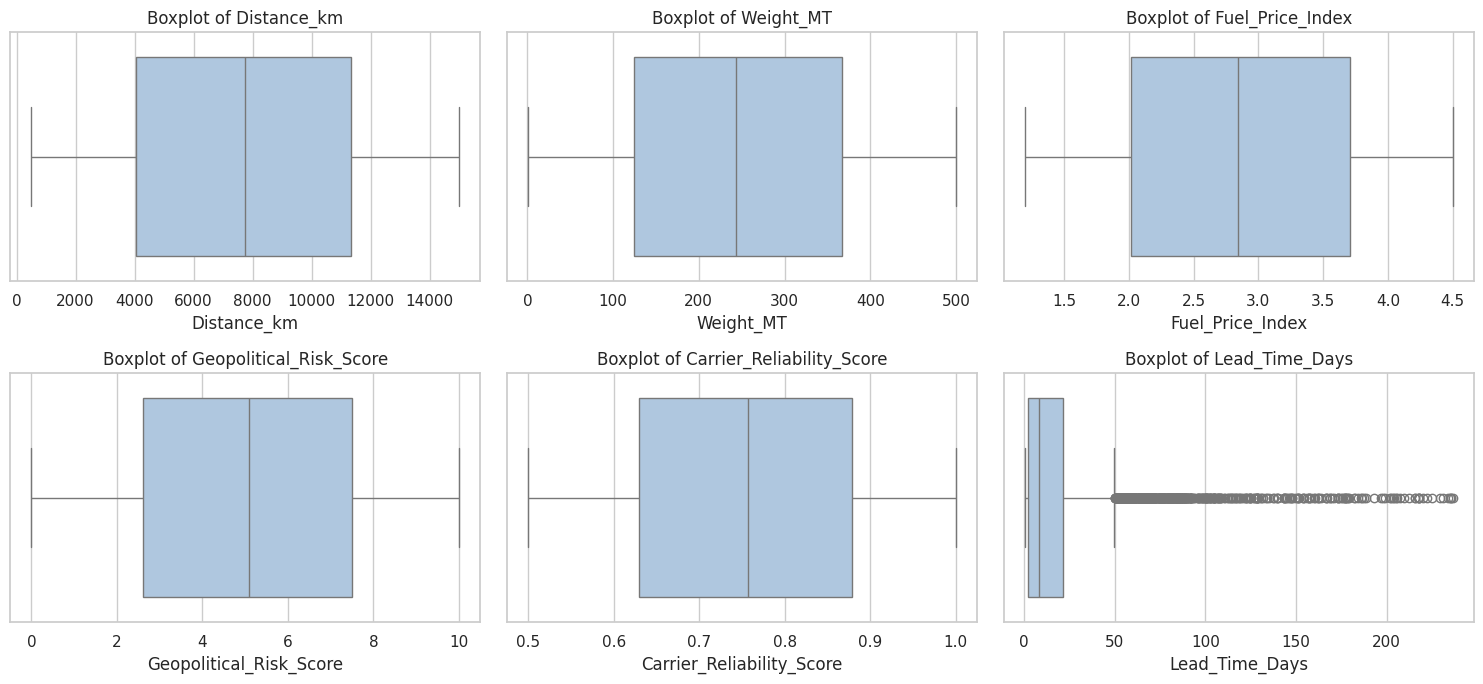

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(x=df[col], ax=ax, color="#A7C7E7")
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

**Insight:** The boxplots confirm the IQR results. Only `Lead_Time_Days` shows many outliers on the right side (very long delivery times).
All other features are clean and within a normal range.

### 4.4 Univariate Analysis: Categorical Features (Count Plots)

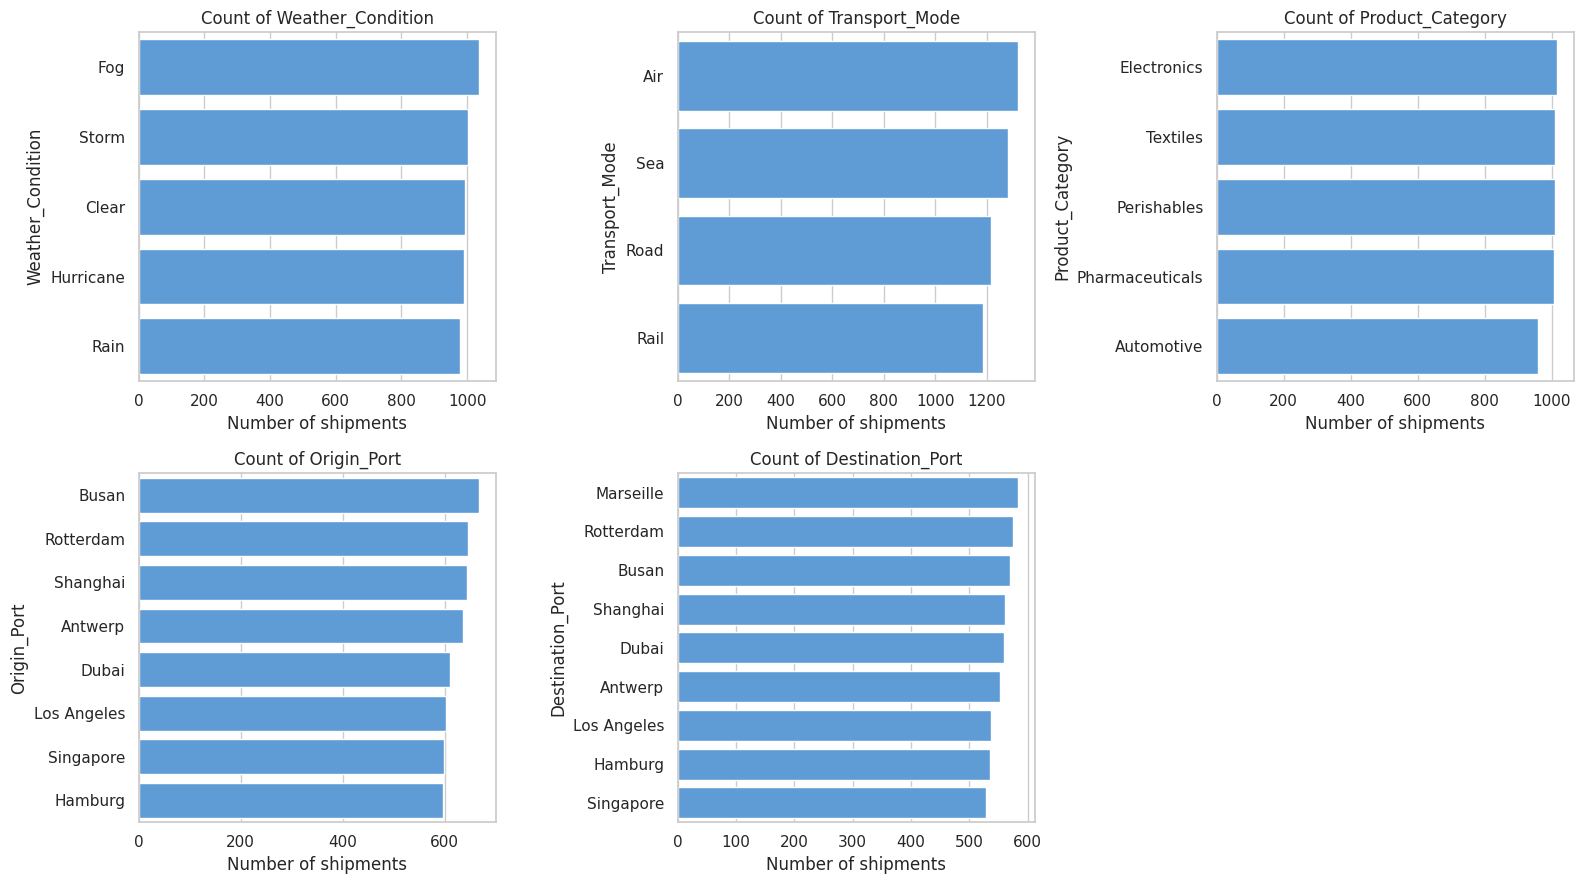

In [ ]:
categorical_cols = ["Weather_Condition", "Transport_Mode", "Product_Category",
                    "Origin_Port", "Destination_Port"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color="#4C9BE8")
    ax.set_title(f"Count of {col}")
    ax.set_xlabel("Number of shipments")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Insight:** All categorical features are **well balanced**: every category has a similar number of shipments
(for example, each weather condition has about 1,000 shipments). No category is too rare, so every category has enough data for the model to learn from.

### 4.5 Bivariate Analysis: Disruption Rate by Category

For each categorical feature we calculate the **disruption rate** (percentage of shipments disrupted) in each category.
The dashed line shows the overall average (about 61%).

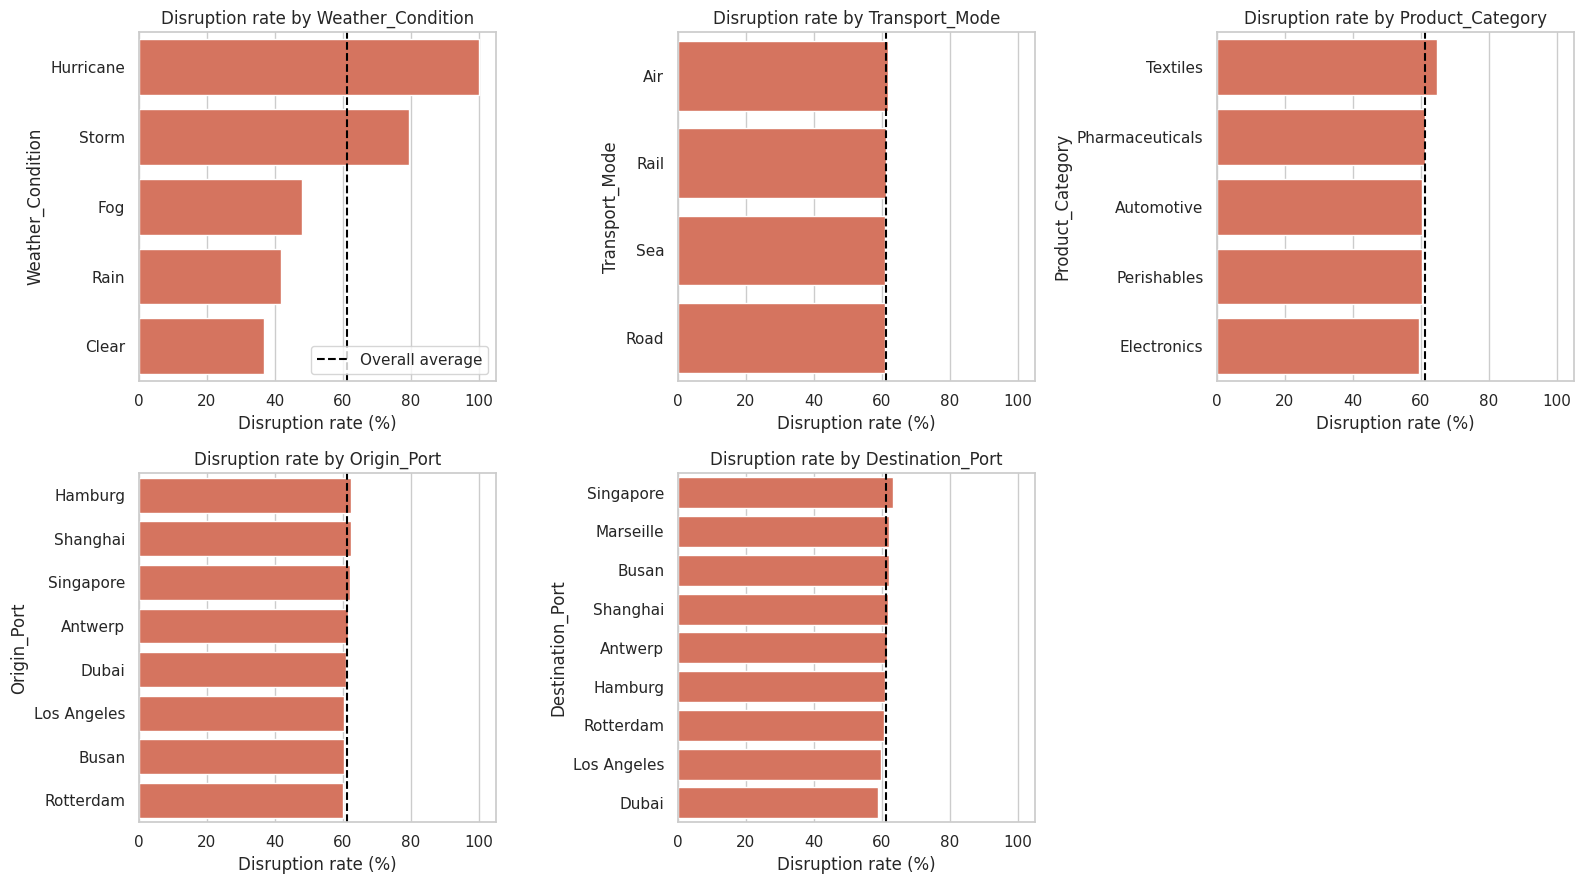

In [ ]:
overall_rate = df["Disruption_Occurred"].mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, categorical_cols):
    rates = df.groupby(col)["Disruption_Occurred"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color="#E8684C")
    ax.axvline(overall_rate * 100, color="black", linestyle="--", label="Overall average")
    ax.set_title(f"Disruption rate by {col}")
    ax.set_xlabel("Disruption rate (%)")
    ax.set_xlim(0, 105)
axes.flat[0].legend(loc="lower right")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# The exact disruption rate for each weather condition
(df.groupby("Weather_Condition")["Disruption_Occurred"]
   .agg(Shipments="count", Disruption_Rate="mean")
   .sort_values("Disruption_Rate", ascending=False)
   .assign(Disruption_Rate=lambda t: (t["Disruption_Rate"] * 100).round(1)))

,Shipments,Disruption_Rate
Weather_Condition,,
Hurricane,990,100.0
Storm,1002,79.5
Fog,1036,48.1
Rain,977,42.0
Clear,995,37.0


**Insights:**

**1. Weather is the strongest factor affecting disruption.**
- Bad weather causes very high disruption rates ,**Hurricane = 100%** and **Storm ≈ 80%**, **Clear** weather has the lowest rate, at about **37%**.
- The gap between bad and clear weather is very large, so weather is a strong predictor of disruption

**2. The other factors have almost no effect.**, Transport mode, product category, and ports** have nearly the same disruption rate across all their categories close to the overall average of **61%**(these values does not change the expected disruption rate, so they are weak predictors)

### 4.6 Bivariate Analysis: Numerical Features vs Target (Boxplots by Class)

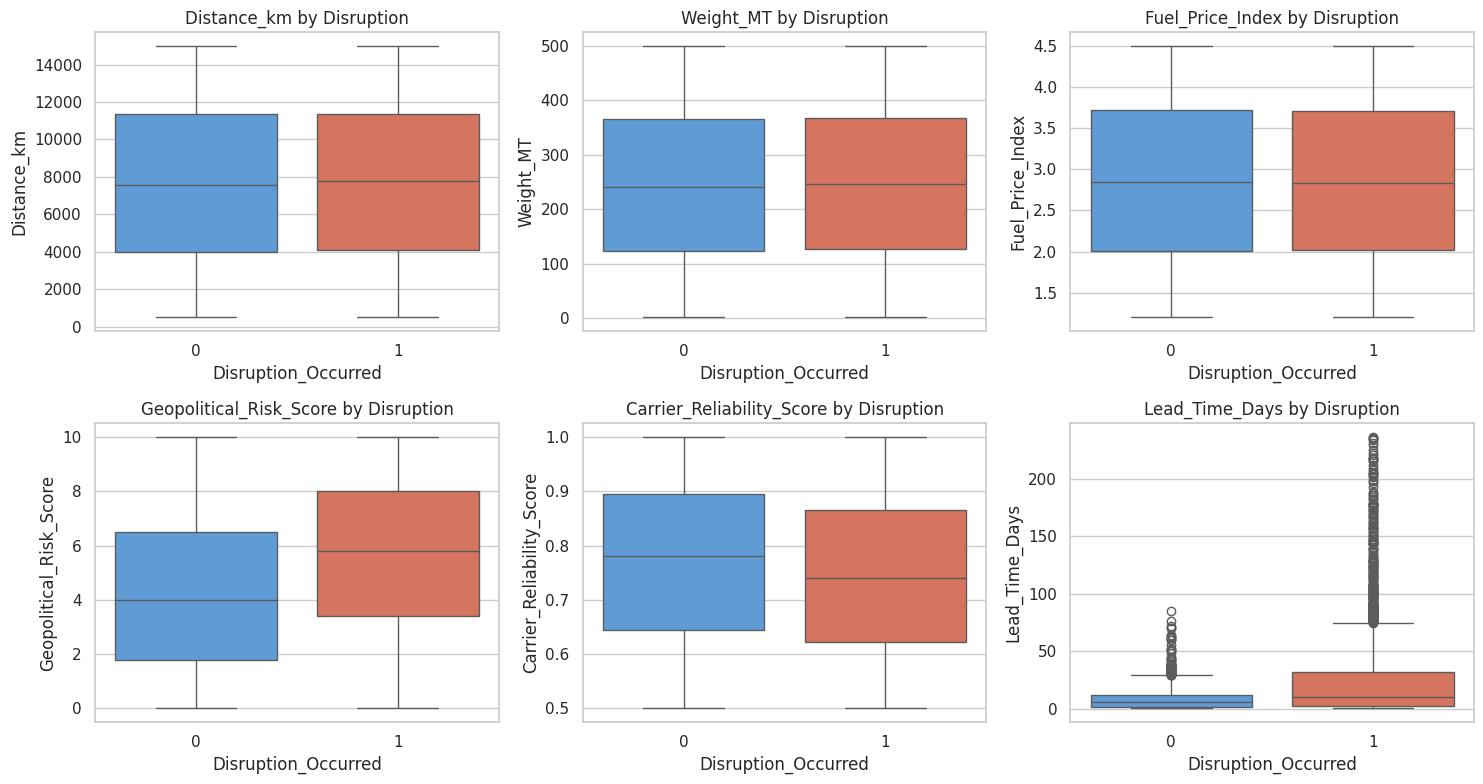

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x="Disruption_Occurred", y=col, ax=ax, palette=["#4C9BE8", "#E8684C"])
    ax.set_title(f"{col} by Disruption")
    ax.set_xlabel("Disruption_Occurred")
plt.tight_layout()
plt.show()

In [ ]:
# Average of each numerical feature for each class
df.groupby("Disruption_Occurred")[numeric_cols].mean().round(3).T

Disruption_Occurred,0,1
Distance_km,7651.761,7737.139
Weight_MT,243.970,247.695
Fuel_Price_Index,2.850,2.857
Geopolitical_Risk_Score,4.262,5.592
Carrier_Reliability_Score,0.769,0.745
Lead_Time_Days,8.885,25.977


**Insights:**
- **Geopolitical_Risk_Score** is clearly **higher** for disrupted shipments: risky routes are disrupted more often.
- **Carrier_Reliability_Score** is slightly **lower** for disrupted shipments: less reliable carriers have more disruptions.
- **Distance, Weight, and Fuel Price** look almost identical in both classes, so they are **weak predictors**.
- **Lead_Time_Days** is much higher for disrupted shipments (about 26 days vs 9 days). This is expected, because a disruption *causes* a longer delivery time.
  We discuss why this column must **not** be used in the model in Section 8.

### 4.7 Disruption Rate by Geopolitical Risk Level

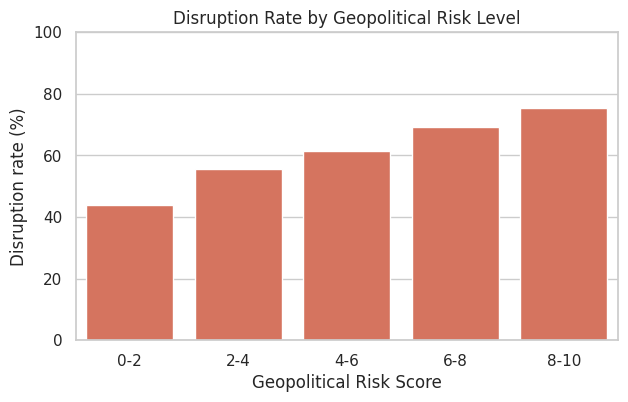

,Disruption_Occurred
Geopolitical_Risk_Score,
0-2,44.1
2-4,55.6
4-6,61.4
6-8,69.2
8-10,75.4


In [ ]:
risk_bins = pd.cut(df["Geopolitical_Risk_Score"], bins=[0, 2, 4, 6, 8, 10],
                   labels=["0-2", "2-4", "4-6", "6-8", "8-10"], include_lowest=True)
risk_rate = df.groupby(risk_bins)["Disruption_Occurred"].mean() * 100

plt.figure(figsize=(7, 4))
sns.barplot(x=risk_rate.index.astype(str), y=risk_rate.values, color="#E8684C")
plt.title("Disruption Rate by Geopolitical Risk Level")
plt.xlabel("Geopolitical Risk Score")
plt.ylabel("Disruption rate (%)")
plt.ylim(0, 100)
plt.show()

risk_rate.round(1)

**Insight:** There is a **clear upward trend**: the disruption rate rises from about **44%** on the safest routes (score 0 to 2)
to about **75%** on the most dangerous routes (score 8 to 10). This makes geopolitical risk the **second most important** factor after weather.

### 4.8 Combined Effect: Weather and Geopolitical Risk

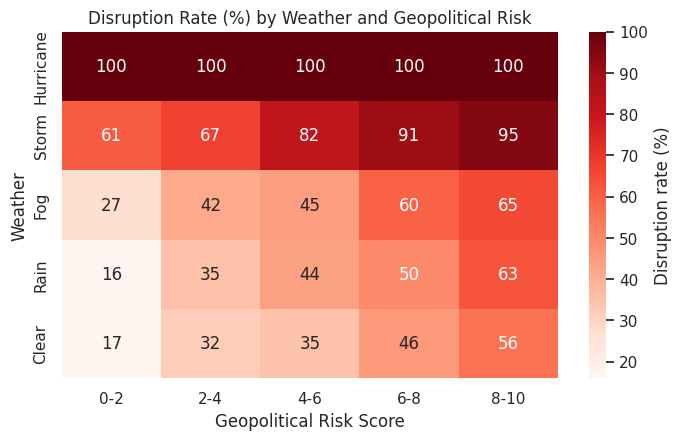

In [ ]:
pivot = (df.assign(Risk_Level=risk_bins)
           .pivot_table(index="Weather_Condition", columns="Risk_Level",
                        values="Disruption_Occurred", aggfunc="mean") * 100)
pivot = pivot.loc[["Hurricane", "Storm", "Fog", "Rain", "Clear"]]

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Disruption rate (%)"})
plt.title("Disruption Rate (%) by Weather and Geopolitical Risk")
plt.xlabel("Geopolitical Risk Score")
plt.ylabel("Weather")
plt.show()

**Insight:** The two strongest factors **add up**. In Clear weather on a safe route (risk 0 to 2) only about **17%** of shipments are disrupted,
but this rises to about **56%** on the riskiest routes. A Storm on a high-risk route reaches about **95%**. Under a Hurricane, every shipment is disrupted regardless of risk.
Both features carry useful information, so the model should use both.

### 4.9 Disruption Rate Over Time

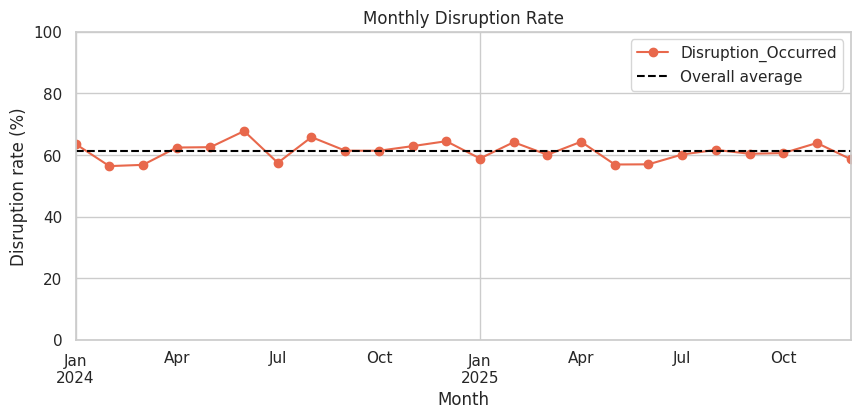

In [ ]:
monthly = df.groupby(df["Date"].dt.to_period("M"))["Disruption_Occurred"].mean() * 100

plt.figure(figsize=(10, 4))
monthly.plot(marker="o", color="#E8684C")
plt.axhline(overall_rate * 100, color="black", linestyle="--", label="Overall average")
plt.title("Monthly Disruption Rate")
plt.ylabel("Disruption rate (%)")
plt.xlabel("Month")
plt.ylim(0, 100)
plt.legend()
plt.show()

**Insight:** The monthly disruption rate stays close to the overall average with no clear trend or seasonality.
The date itself does not help predict disruptions, so we will **not** use it as a feature.

### 4.10 Correlation Heatmap

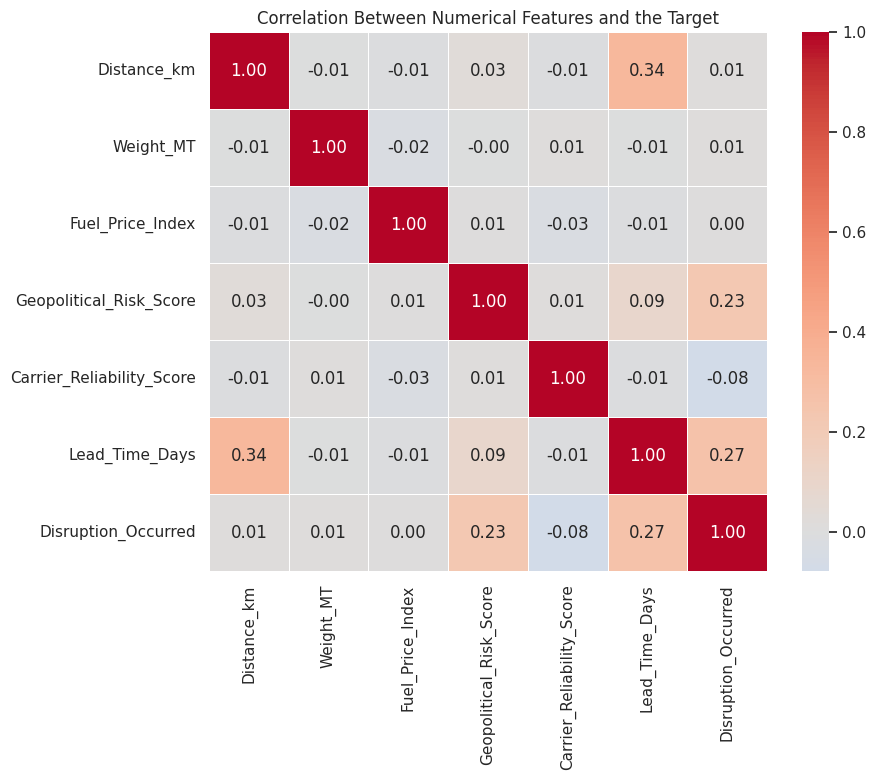

In [ ]:
corr = df[numeric_cols + ["Disruption_Occurred"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Between Numerical Features and the Target")
plt.show()

**Insights:**
- The numerical features are barely correlated with each other (most values are close to 0).
  This is a good sign, because Naive Bayes assumes the features are independent.
- `Geopolitical_Risk_Score` is the input most linked to our target (around +0.23), so the higher the risk, the more likely a disruption.
  `Carrier_Reliability_Score` comes next with a weak negative link (around -0.08): more reliable carriers see slightly fewer disruptions.
- `Lead_Time_Days` shows the strongest relationship with the target (around +0.27), but we shouldn't depend on it.
  Lead time is a consequence of disruption not a cause (using it would cause data leakage)

### 4.11 EDA Summary
Weather turned out to be the clearest driver of disruption: every shipment that ran into a hurricane was disrupted, compared with only 37% under clear skies.

Geopolitical risk also plays a big role, with disruption rates climbing from about 44% at low risk to 75% at high risk. Carrier reliability has a weaker effect, though less reliable carriers still tend to see more disruptions.

The remaining features (distance, weight, fuel price, transport mode, product category, and ports) show very little effect on their own. We still keep them in the model, since Naive Bayes usually isn't hurt much by weak features and they may add a small amount of signal.

A few columns will be left out. `Date` carries no useful signal, and `Shipment_ID` is just an identifier. `Lead_Time_Days` is strongly related to disruption, but we only know it after the shipment is delivered. Including it would cause data leakage, so we drop it before training.

## 5. Prepare Data for modeling
### 5.1 Avoiding Data Leakage
By dropping `Lead_Time_Days` because it reflects the outcome rather than predicting it.Keeping it would make the model look great in testing, but it would be useless in practice

### 5.2 Select Features (X) and Target (y)

In [ ]:
target = "Disruption_Occurred"

numeric_features = ["Distance_km", "Weight_MT", "Fuel_Price_Index",
                    "Geopolitical_Risk_Score", "Carrier_Reliability_Score"]
categorical_features = ["Origin_Port", "Destination_Port", "Transport_Mode",
                        "Product_Category", "Weather_Condition"]

# removed to avoid data leckage
dropped = ["Shipment_ID", "Date", "Lead_Time_Days"]

X = df[numeric_features + categorical_features]
y = df[target]

print("Features used :", X.shape[1])
print("Dropped       :", dropped)
X.head()

Features used : 10
Dropped       : ['Shipment_ID', 'Date', 'Lead_Time_Days']


,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Weather_Condition
0,5930.83,197.42,2.43,5.0,0.865,Singapore,Los Angeles,Rail,Textiles,Hurricane
1,14285.36,237.24,2.30,7.5,0.592,Singapore,Shanghai,Rail,Automotive,Storm
2,11113.91,427.42,1.78,5.6,0.673,Rotterdam,Los Angeles,Rail,Perishables,Rain
3,9180.55,170.66,3.20,0.8,0.832,Busan,Hamburg,Rail,Electronics,Hurricane
4,2762.27,434.96,2.77,1.9,0.741,Busan,Singapore,Air,Perishables,Fog


### 5.3 Encode Categorical Variables (One-Hot Encoding)
We convert each categorical column into 0/1 columns

In [ ]:
X_encoded = pd.get_dummies(X, columns=categorical_features, dtype=int)
print("Shape after encoding:", X_encoded.shape)
X_encoded.head()

Shape after encoding: (5000, 36)


,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Origin_Port_Antwerp,Origin_Port_Busan,Origin_Port_Dubai,Origin_Port_Hamburg,Origin_Port_Los Angeles,...,Product_Category_Automotive,Product_Category_Electronics,Product_Category_Perishables,Product_Category_Pharmaceuticals,Product_Category_Textiles,Weather_Condition_Clear,Weather_Condition_Fog,Weather_Condition_Hurricane,Weather_Condition_Rain,Weather_Condition_Storm
0,5930.83,197.42,2.43,5.0,0.865,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
1,14285.36,237.24,2.30,7.5,0.592,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
2,11113.91,427.42,1.78,5.6,0.673,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
3,9180.55,170.66,3.20,0.8,0.832,0,1,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,2762.27,434.96,2.77,1.9,0.741,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0


### 5.4 Train/Test Split


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
) # We use stratify=y so both sets keep the same 61% / 39% class balance.

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Disruption rate in train:", round(y_train.mean(), 3))
print("Disruption rate in test :", round(y_test.mean(), 3))

Train: (4000, 36) | Test: (1000, 36)
Disruption rate in train: 0.612
Disruption rate in test : 0.613


### 5.5 Feature Scaling: Do we need it?
**No, Gaussian NB doesn't need scaling.**
It looks at each feature on its own and learns that feature's own mean and spread. So whether distance is in kilometers or meters, the model makes the same decisions. Scaling would just change the numbers, not the results.

## 6. Model Training: Gaussian Naive Bayes (Baseline)

We train Gaussian Naive Bayes model on all the prepared features.

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# What the model learned
print("Learned class priors:", dict(zip(["No Disruption", "Disruption"], gnb.class_prior_.round(3))))

# The mean of each numeric feature(the centre of each bell curve)
pd.DataFrame(gnb.theta_, columns=X_train.columns, index=["Class 0", "Class 1"])[numeric_features].round(3)

Learned class priors: {'No Disruption': np.float64(0.388), 'Disruption': np.float64(0.612)}


,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score
Class 0,7683.983,244.505,2.847,4.238,0.767
Class 1,7708.766,246.249,2.859,5.593,0.745


**What did the model learn?**
- The priors are just the class proportions in the training data: about 39% of shipments had no disruption and 61% did
- For each feature, the model calculated an average (`theta_`) and a spread (`var_`) for each class separately. So every feature gets two bell curves, one for disrupted shipments and one for normal ones
- For example, disrupted shipments have a higher average `Geopolitical_Risk_Score` So when a new shipment comes in with a high risk score, the model leans toward "Disruption"

### 6.1 Baseline Evaluation


In [ ]:
def evaluate(model, X_te, y_te, name):

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC_AUC": roc_auc_score(y_te, y_prob),
    }

baseline = evaluate(gnb, X_test, y_test, "Gaussian NB (our baseline)")
pd.DataFrame([baseline]).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Gaussian NB (our baseline),0.704,0.897,0.584,0.708,0.807


In [ ]:
print(classification_report(y_test, gnb.predict(X_test),
                            target_names=["No Disruption", "Disruption"]))

               precision    recall  f1-score   support

No Disruption       0.58      0.89      0.70       387
   Disruption       0.90      0.58      0.71       613

     accuracy                           0.70      1000
    macro avg       0.74      0.74      0.70      1000
 weighted avg       0.77      0.70      0.70      1000



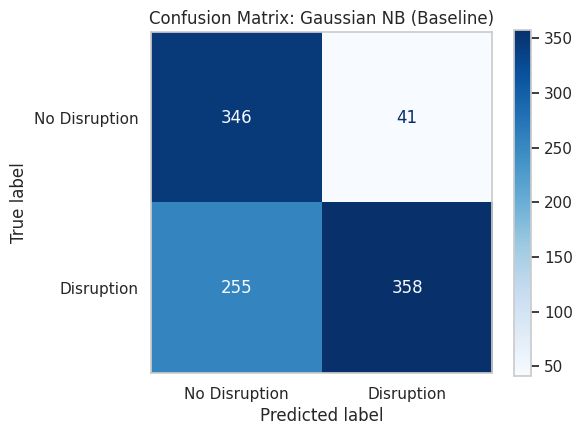

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(gnb, X_test, y_test, cmap="Blues", ax=ax,
                                      display_labels=["No Disruption", "Disruption"])
plt.title("Confusion Matrix: Gaussian NB (Baseline)")
plt.grid(False)
plt.show()


**In supply chain, Recall is very important. Why?**
Because missing a real disruption (False Negative) costs much more than a false alarm so if  the model misses a disruption nobody prepares which leads to delays and stock shortages

### Interpretation of the Baseline
- Accuracy (70%): The model gets about 70% of shipments right which beats the 61% we'd get by always predicting a disruption
- Precision (0.90):When the model flags a disruption, it's almost always correct
- Recall (~0.58): This is the weak spot. The model misses roughly 4 out of every 10 real disruptions which shows up as the large False Negative cell in the confusion matrix
- ROC AUC (~0.81): The model is good at ranking shipments by risk. The problem is that it's too cautious when making the final yes/no call so lowering the decision threshold could help catch more disruptions


**Why does this happen?** Gaussian NB assumes that every feature follows the same shape: a bell curve.
However after encoding, the weather condition columns only contain two values, 0 and 1 so they can't form a bell shape

## 7. Improving Naive Bayes (Fixing the Limitations)
We now try three fixes and compare each one with the baseline.

1- **Tuned Gaussian NB:** We search for the best `var_smoothing` value using cross-validation this fixes the zero variance problem

2- **Mixed Naive Bayes:** We use Gaussian NB for the numeric features and Categorical NB (with Laplace smoothing) for the categorical ones this fixes the wrong distribution problem and the zero frequency problem

3- **Categorical NB:** We turn the numeric features into 5 bins, then use Categorical NB for all features this also fixes the wrong distribution and zero frequency problems


### 7.1 Version A: Tuning `var_smoothing`


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gnb_search = GridSearchCV(
    make_pipeline(StandardScaler(), GaussianNB()),
    param_grid={"gaussiannb__var_smoothing": np.logspace(-9, 0, 30)},
    scoring="f1", cv=cv
)
gnb_search.fit(X_train, y_train)
gnb_tuned = gnb_search.best_estimator_

print("Best var_smoothing:", gnb_search.best_params_["gaussiannb__var_smoothing"])
print("Best CV F1        :", round(gnb_search.best_score_, 3))

Best var_smoothing: 1.0
Best CV F1        : 0.745


`var_smoothing` adds a small value to each variance so none of them can be zero we try different values with 5-fold cross-validation and keep the one with the best F1 score we scale the features first the added value depends on the largest variance so without scaling, big features like `Distance_km` would take over

### 7.2 Version B: Mixed Naive Bayes (Gaussian + Categorical)


In [ ]:
class MixedNB(BaseEstimator, ClassifierMixin):
    # Naive Bayes that uses GaussianNB for numeric columns and CategoricalNB for categorical columns

    def __init__(self, numeric_cols, categorical_cols, alpha=1.0):
        self.numeric_cols = numeric_cols
        self.categorical_cols = categorical_cols
        self.alpha = alpha

    def _encode(self, X):
        # Turn each category into an integer code, using the categories seen during training
        return np.column_stack([
            pd.Categorical(X[c], categories=self.categories_[c]).codes
            for c in self.categorical_cols
        ])

    def fit(self, X, y):
        self.categories_ = {c: sorted(X[c].unique()) for c in self.categorical_cols}
        self.gnb_ = GaussianNB().fit(X[self.numeric_cols], y)
        self.cnb_ = CategoricalNB(alpha=self.alpha).fit(self._encode(X), y)
        self.classes_ = self.gnb_.classes_
        return self

    def predict_proba(self, X):
        # Both parts include the log prior, so we subtract it once to count it only one time
        joint = (self.gnb_.predict_joint_log_proba(X[self.numeric_cols])
                 + self.cnb_.predict_joint_log_proba(self._encode(X))
                 - np.log(self.gnb_.class_prior_))
        joint -= joint.max(axis=1, keepdims=True)  # for numerical stability
        prob = np.exp(joint)
        return prob / prob.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

# This model works on the raw (not one-hot encoded) columns, using the same train/test rows
X_train_raw, X_test_raw = X.loc[X_train.index], X.loc[X_test.index]

mixed_nb = MixedNB(numeric_features, categorical_features, alpha=1.0)
mixed_nb.fit(X_train_raw, y_train)
print("Mixed Naive Bayes trained.")

Mixed Naive Bayes trained.


Since Naive Bayes looks at each feature on its own we can use a different distribution for each type. Numeric features get a bell curve and categorical features use how often each category shows up For the categorical part we add 1 to every count (Laplace smoothing) so even a combination we never saw like a hurricane with no disruption gets a small probability instead of zero to get the final score for each class we just add the log of the prior to the log of both parts scikit-learn doesn't have this built in, so we wrote a small class for it

### 7.3 Version C: Categorical Naive Bayes on Binned Features


In [ ]:
binner = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")

def to_categorical_codes(X_part, fit=False):
    # Bin numeric columns and turn categorical columns into integer codes
    num = binner.fit_transform(X_part[numeric_features]) if fit else binner.transform(X_part[numeric_features])
    cat = np.column_stack([
        pd.Categorical(X_part[c], categories=sorted(X[c].unique())).codes for c in categorical_features
    ])
    return np.column_stack([num, cat]).astype(int)

X_train_cat = to_categorical_codes(X_train_raw, fit=True)   # bins learned on training data only
X_test_cat = to_categorical_codes(X_test_raw)

cat_nb = CategoricalNB(alpha=1.0)
cat_nb.fit(X_train_cat, y_train)
print("Categorical Naive Bayes trained on", X_train_cat.shape[1], "features.")

Categorical Naive Bayes trained on 10 features.


Another way to deal with features that aren't bell-shaped is to drop the bell curve idea completely we split each numeric feature into 5 groups with about the same number of shipments in each so every feature becomes categorical then we use Categorical NB with Laplace smoothing on all of them.

### 7.4 Comparing the Naive Bayes Versions

In [ ]:
nb_results = pd.DataFrame([
    baseline,
    evaluate(gnb_tuned, X_test, y_test, "A. Gaussian NB (tuned var_smoothing)"),
    evaluate(mixed_nb, X_test_raw, y_test, "B. Mixed NB (Gaussian + Categorical)"),
    evaluate(cat_nb, X_test_cat, y_test, "C. Categorical NB (binned)"),
]).set_index("Model").round(3)
nb_results

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Gaussian NB (our baseline),0.704,0.897,0.584,0.708,0.807
A. Gaussian NB (tuned var_smoothing),0.728,0.853,0.672,0.752,0.814
B. Mixed NB (Gaussian + Categorical),0.731,0.777,0.788,0.782,0.824
C. Categorical NB (binned),0.745,0.791,0.794,0.793,0.825


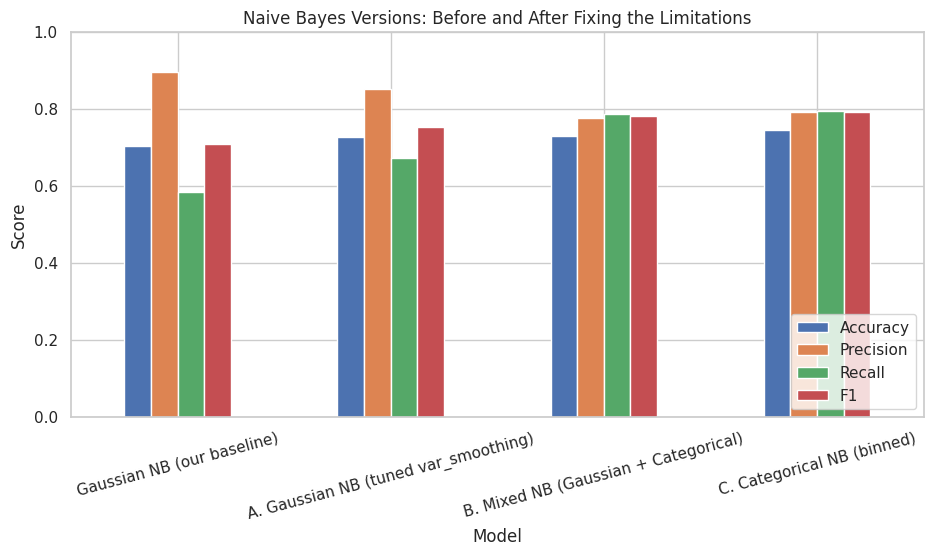

In [ ]:
nb_results[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 5), rot=15)
plt.title("Naive Bayes Versions: Before and After Fixing the Limitations")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

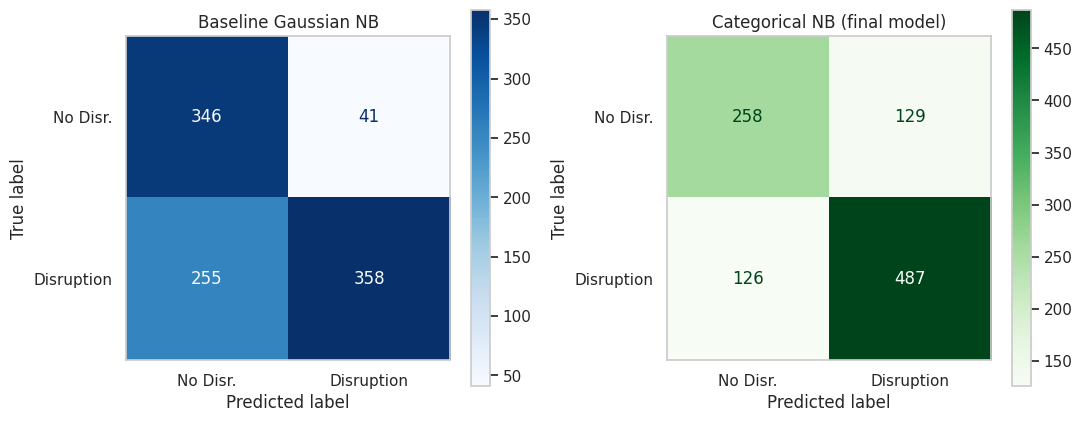

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, gnb.predict(X_test), cmap="Blues", ax=axes[0],
                                        display_labels=["No Disr.", "Disruption"])
axes[0].set_title("Baseline Gaussian NB")
ConfusionMatrixDisplay.from_predictions(y_test, cat_nb.predict(X_test_cat), cmap="Greens", ax=axes[1],
                                        display_labels=["No Disr.", "Disruption"])
axes[1].set_title("Categorical NB (final model)")
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

### Interpretation
Tuning `var_smoothing` (A) helped a bit because it stopped the near-zero variance of the hurricane column from taking over
The real jump came from Mixed NB (B) and Categorical NB (C) where recall went from about 0.58 to 0.80 and F1 went from 0.71 to 0.79
Treating the weather columns as categories instead of bell curves let the model use all the weather information and not just hurricanes
The model now catches about 8 out of 10 disruptions instead of 6
It raises a few more false alarms but that is a fair trade in supply chain because missing a disruption costs much more than an extra warning
Overall the limitations of Naive Bayes did show up in practice but we could fix them by picking the right type of Naive Bayes for each kind of data

### 7.5 Why Our Final Model is Categorical NB
We started with Gaussian NB as our baseline, and we finish with Categorical NB as our final model.

- This is not a different algorithm: both use the same Bayes' theorem, the same prior and the same independence assumption

| | Gaussian NB (our baseline) | Categorical NB (our final model) |
|---|---|---|
| How it calculates $P(x \mid \text{class})$ | Fits a **bell curve** (mean and variance) to each feature | **Counts** how often each value appears in each class |
| Assumption about the data | Every feature is bell-shaped (normal) | None, it only needs categories |
| Our 0/1 weather columns | Do not fit a bell curve | Handled naturally as categories |
| Hurricane never seen with "No Disruption" | Variance becomes almost **0**, the curve becomes a spike and dominates the prediction | **Laplace smoothing** adds 1 to every count, so the probability is small but **not zero** |
| Numeric features (risk, reliability, ...) | Used directly | Split into **5 bins** first (e.g. risk 7.3 goes to the "6 to 8" bin) |
| Recall on the test set | 0.584 | 0.794 |
| F1 on the test set | 0.708 | 0.793 |

The cell below shows the problem and the fix with the real numbers learned by the two models.

In [ ]:
# 1) Gaussian NB: variance of the one-hot Hurricane column inside each class
hurr_col = [c for c in X_train.columns if "Hurricane" in c][0]
j = list(X_train.columns).index(hurr_col)
print(f"Gaussian NB, column '{hurr_col}':")
for k, cls in enumerate(gnb.classes_):
    print(f"   class {cls}: mean = {gnb.theta_[k, j]:.4f}   variance = {gnb.var_[k, j]:.2e}")

# 2) Categorical NB: P(Weather = Hurricane | class) after Laplace smoothing
w_idx = len(numeric_features) + categorical_features.index("Weather_Condition")
weather_levels = sorted(X["Weather_Condition"].unique())
probs = np.exp(cat_nb.feature_log_prob_[w_idx])
print("\nCategorical NB, P(Weather | class):")
print(pd.DataFrame(probs.T, index=weather_levels,
                   columns=[f"class {c}" for c in cat_nb.classes_]).round(4))

Gaussian NB, column 'Weather_Condition_Hurricane':
   class 0: mean = 0.0000   variance = 1.78e-02
   class 1: mean = 0.3216   variance = 2.36e-01

Categorical NB, P(Weather | class):
           class 0  class 1
Clear       0.3293   0.1230
Fog         0.2701   0.1625
Hurricane   0.0006   0.3214
Rain        0.2939   0.1316
Storm       0.1061   0.2615


**What we found:**
- In Gaussian NB, the hurricane column in class 0 is all zeros so its real variance is exactly 0 the 0.018 we see is just the small value `var_smoothing` adds to avoid dividing by zero next to class 1 (about 0.24), the class 0 bell curve is a thin spike at 0 so any shipment with a hurricane gets a class 0 likelihood of about $e^{-28}$, which is basically zero. That one column ends up overpowering everything else and the model barely uses Storm Fog or Rain
- In Categorical NB, Laplace smoothing gives hurricanes in class 0 a small probability instead of zero, and every weather type gets a sensible probability straight from the counts

**Decision:** we go with Categorical NB as our final model. It fixes both problems we saw (wrong distribution and zero frequency) raises recall from about 0.58 to 0.79 and is still fast and easy to explain

## 8. Comparing Naive Bayes with Other Classification Models

To judge Naive Bayes fairly, we compare it with four other popular classifiers on exactly the same data.

### 8.1 How the models differ
| Model | How it decides | Needs scaling? | Learns feature interactions? | Speed | Easy to explain? |
|---|---|---|---|---|---|
| **Naive Bayes** | Uses probabilities from Bayes' theorem, assuming independent features | No | No | Very fast | Yes (priors and likelihoods) |
| **Logistic Regression** | Learns a weight for each feature and draws a straight (linear) boundary | Yes | No (unless added manually) | Fast | Yes (feature weights) |
| **K-Nearest Neighbors** | Looks at the K most similar shipments and takes a majority vote | Yes | Yes (indirectly) | Slow at prediction time | Medium |
| **Decision Tree** | Asks a series of yes/no questions (e.g. "Is weather = Hurricane?") | No | Yes | Fast | Yes (visual rules) |
| **Random Forest** | Combines hundreds of decision trees and takes a vote | No | Yes | Slower | Harder (many trees) |

**Key difference:** Naive Bayes is a **generative** model (it learns how each class "looks" and then applies Bayes' theorem),
while Logistic Regression is a **discriminative** model (it directly learns the boundary between classes).
Trees and KNN do not assume any distribution at all.

### 8.2 Train and evaluate all models
Scaling is placed inside a `Pipeline` for the models that need it.

In [ ]:
other_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "K-Nearest Neighbors (K=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Decision Tree (depth=5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest (300 trees)": RandomForestClassifier(n_estimators=300, max_depth=8,
                                                        random_state=RANDOM_STATE, n_jobs=-1),
}

comparison = [
    evaluate(gnb, X_test, y_test, "Gaussian NB (our baseline)"),
    evaluate(cat_nb, X_test_cat, y_test, "Categorical NB (final, fixed)"),
]
for name, model in other_models.items():
    model.fit(X_train, y_train)
    comparison.append(evaluate(model, X_test, y_test, name))

comparison = pd.DataFrame(comparison).set_index("Model").round(3).sort_values("F1", ascending=False)
comparison

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
"Categorical NB (final, fixed)",0.745,0.791,0.794,0.793,0.825
Logistic Regression,0.742,0.784,0.799,0.792,0.828
Random Forest (300 trees),0.732,0.766,0.811,0.788,0.820
Decision Tree (depth=5),0.727,0.766,0.799,0.782,0.808
K-Nearest Neighbors (K=15),0.686,0.711,0.822,0.762,0.755
Gaussian NB (our baseline),0.704,0.897,0.584,0.708,0.807


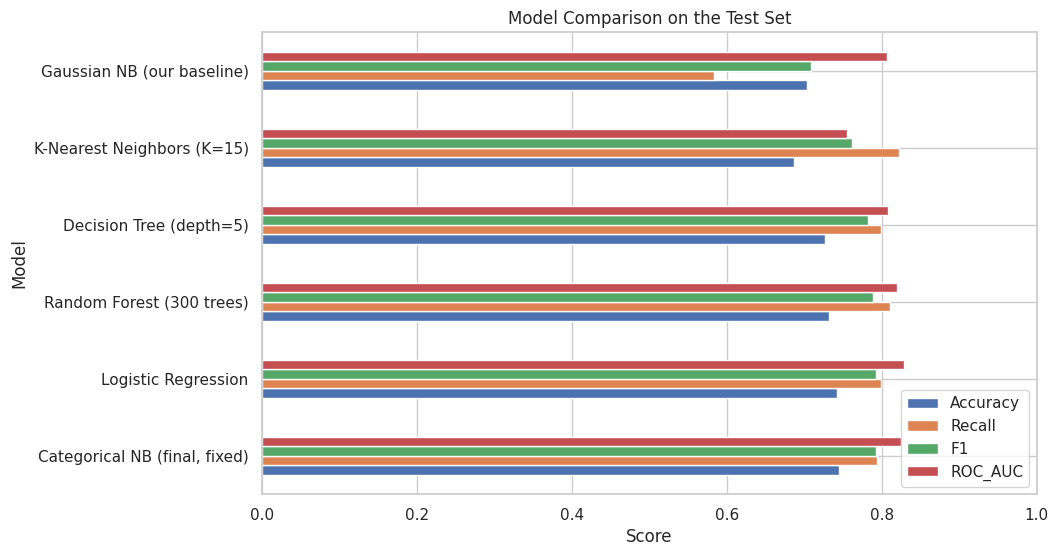

In [ ]:
comparison[["Accuracy", "Recall", "F1", "ROC_AUC"]].plot(kind="barh", figsize=(10, 6))
plt.title("Model Comparison on the Test Set")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.show()

### 8.3 ROC Curves


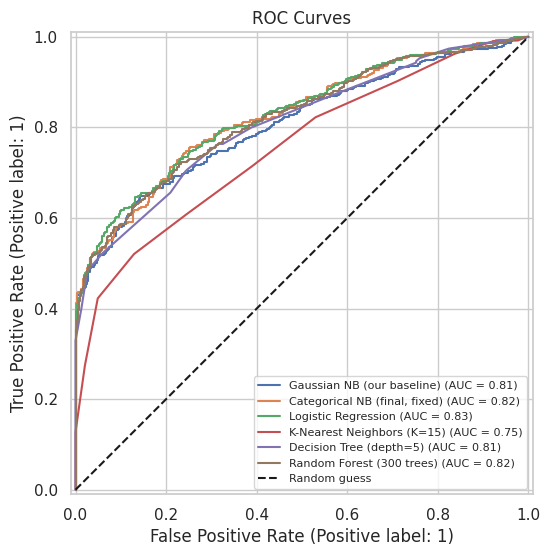

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_estimator(gnb, X_test, y_test, name="Gaussian NB (our baseline)", ax=ax)
RocCurveDisplay.from_predictions(y_test, cat_nb.predict_proba(X_test_cat)[:, 1], name="Categorical NB (final, fixed)", ax=ax)
for name, model in other_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### 8.4 A more reliable check: 5-Fold Cross-Validation


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

# Categorical NB as a full pipeline, so the binning is re-learned inside every fold (no leakage)
cat_nb_pipeline = make_pipeline(
    ColumnTransformer([
        ("bin", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), numeric_features),
        ("cat", OrdinalEncoder(), categorical_features),
    ]),
    CategoricalNB(alpha=1.0, min_categories=10),
)

cv_models = {
    "Gaussian NB (our baseline)": (GaussianNB(), X_train),
    "Categorical NB (final, fixed)": (cat_nb_pipeline, X_train_raw),
    **{name: (model, X_train) for name, model in other_models.items()},
}

cv_rows = []
for name, (model, data) in cv_models.items():
    scores = cross_validate(model, data, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    cv_rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV F1 (std)": scores["test_f1"].std(),
        "CV ROC_AUC": scores["test_roc_auc"].mean(),
        "Fit time (s)": scores["fit_time"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV F1", ascending=False)
cv_results.round(3)

,CV Accuracy,CV F1,CV F1 (std),CV ROC_AUC,Fit time (s)
Model,,,,,
Random Forest (300 trees),0.741,0.791,0.016,0.824,2.223
Logistic Regression,0.739,0.786,0.013,0.826,0.049
"Categorical NB (final, fixed)",0.737,0.783,0.018,0.823,0.036
Decision Tree (depth=5),0.726,0.779,0.017,0.813,0.017
K-Nearest Neighbors (K=15),0.693,0.767,0.017,0.758,0.013
Gaussian NB (our baseline),0.706,0.710,0.012,0.806,0.010


### 8.5 Interpretation of the Comparison
- Our final model Categorical NB, holds its own against the strongest models It reaches about the same scores as Logistic Regression and Random Forest (around 74% accuracy 0.79 F1 and 0.82 ROC AUC) with only about a point between them
- Naive Bayes is by far the fastest to train, and Categorical NB is close behind. Random Forest is dozens of times slower since it builds 300 trees.
- KNN does the worst With so many weak and one-hot features the distance between shipments stops being very meaningful
- Decision Tree comes close to the top and is easy to explain, but it's less stable than Random Forest
- Since all the good models top out at around 74%, the limit seems to come from the data rather than the algorithm The features we have, mainly weather and geopolitical risk just can't explain every disruption

**Why does Naive Bayes do so well here?**
- The EDA showed that the input features are barely correlated with each other so the "naive" independence assumption is close to true for this dataset, and Naive Bayes loses very little by relying on it

### 8.6 Hyperparameter Tuning for Categorical NB
Our initial Categorical Naive Bayes model used 5 bins and alpha=1.0.
Instead of choosing these values manually, we test different combinations
using cross-validation and select the combination with the best F1 score.

We tune:

- `n_bins`: controls how finely numeric features are discretized.
- `alpha`: controls the amount of Laplace smoothing.

In [ ]:
# Hyperparameter values to test
n_bins_values = [3, 4, 5, 6, 8, 10]
alpha_values = [0.1, 0.5, 1.0, 2.0, 5.0]

tuning_results = []

for n_bins in n_bins_values:

    temp_binner = KBinsDiscretizer(
        n_bins=n_bins,
        encode="ordinal",
        strategy="quantile"
    )

    # Bin numeric features using training data
    X_train_num_binned = temp_binner.fit_transform(
        X_train_raw[numeric_features]
    )

    # Convert categorical features to integer codes
    X_train_cat_codes = np.column_stack([
        pd.Categorical(
            X_train_raw[c],
            categories=sorted(X[c].unique())
        ).codes
        for c in categorical_features
    ])

    X_train_tuned = np.column_stack([
        X_train_num_binned,
        X_train_cat_codes
    ]).astype(int)

    for alpha in alpha_values:

        model = CategoricalNB(alpha=alpha)

        scores = cross_val_score(
            model,
            X_train_tuned,
            y_train,
            cv=cv,
            scoring="f1"
        )

        tuning_results.append({
            "n_bins": n_bins,
            "alpha": alpha,
            "Mean CV F1": scores.mean()
        })

tuning_results = pd.DataFrame(tuning_results)
tuning_results.head(10)

,n_bins,alpha,Mean CV F1
0,3,0.1,0.780209
1,3,0.5,0.780458
2,3,1.0,0.780712
3,3,2.0,0.780651
4,3,5.0,0.782262
5,4,0.1,0.778071
6,4,0.5,0.778169
7,4,1.0,0.778169
8,4,2.0,0.778003
9,4,5.0,0.777630


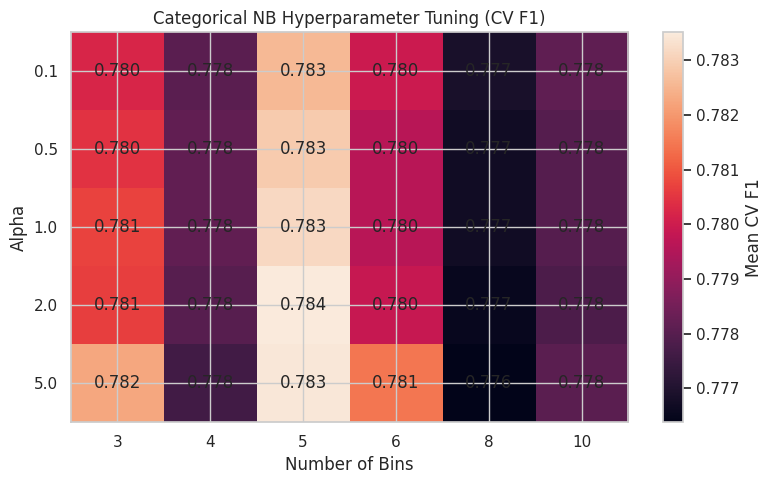

In [ ]:
heatmap_data = tuning_results.pivot(
    index="alpha",
    columns="n_bins",
    values="Mean CV F1"
)

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(heatmap_data.values, aspect="auto")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Number of Bins")
ax.set_ylabel("Alpha")
ax.set_title("Categorical NB Hyperparameter Tuning (CV F1)")

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j,
            i,
            f"{heatmap_data.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, label="Mean CV F1")
plt.tight_layout()
plt.show()

**Observation:**  
Hyperparameter tuning showed very similar F1 scores across the tested values of `n_bins` and `alpha`.  
Since no meaningful performance improvement was observed, we retained the original configuration (`n_bins=5`, `alpha=1.0`) for the final Categorical Naive Bayes model.

## 9. Conclusion and Key Insights

### What we did
We set out to predict whether an international shipment will be disrupted (`Disruption_Occurred`) using only information available before it leaves. After exploring the data and removing a column that leaked the answer, we trained Gaussian Naive Bayes as a baseline. It struggled because its bell-curve assumption didn't fit the 0/1 weather columns, and the hurricane column ended up with zero variance in one class. Switching to Categorical Naive Bayes fixed this, and we then compared it with four other classifiers.

### Key Insights:
1. The baseline Gaussian NB reached about 70% accuracy with high precision, but its recall was low and it missed many disruptions.
2. The main reason was the wrong distribution: the 0/1 weather columns aren't bell-shaped, and the hurricane column had zero variance for one class.
3. Tuning `var_smoothing` helped a little, but the real gain came from using the right distribution (Categorical and Mixed NB). Recall went from about 0.58 to 0.80 and F1 from 0.71 to 0.79.
4. The improved Naive Bayes ended up within about a point of Logistic Regression and Random Forest, while being much faster than Random Forest and easier to explain.
